# Exploratory data analysis: Medical Abstracts TC Corpus

**Goal:** understand the data behind the triage classifier before modeling it: how the categories are distributed, how long the texts are, and whether the labels can be trusted.

**Main finding:** the same abstract often appears more than once with *different* labels, including across the train/test split. Left as is, no model could be evaluated fairly, so ambiguous texts are removed (`src/data_cleaning.py`) before training.

The model itself is trained by `src/train.py`. This notebook only explores the data and justifies the data decisions.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works from the repository root and from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data_cleaning import remove_ambiguous_texts

DATA_DIR = ROOT / "data" / "raw"
train_df = pd.read_csv(DATA_DIR / "medical_tc_train.csv")
test_df = pd.read_csv(DATA_DIR / "medical_tc_test.csv")
labels_df = pd.read_csv(DATA_DIR / "medical_tc_labels.csv")

print(f"train: {train_df.shape} | test: {test_df.shape} | labels: {labels_df.shape}")

train: (11550, 2) | test: (2888, 2) | labels: (5, 2)


## 1. The data

Three files: the training set, the test set, and a dictionary that maps each numeric label to a condition name. Each row is a medical abstract (title and text together) with exactly one label.

In [2]:
display(labels_df)
display(train_df.head(3))

,condition_label,condition_name
0,1,neoplasms
1,2,digestive system diseases
2,3,nervous system diseases
3,4,cardiovascular diseases
4,5,general pathological conditions


,condition_label,medical_abstract
0,5,Tissue changes around loose prostheses. A cani...
1,1,Neuropeptide Y and neuron-specific enolase lev...
2,2,"Sexually transmitted diseases of the colon, re..."


## 2. Class balance

In [3]:
class_share = pd.DataFrame(
    {
        "train": train_df["condition_label"].value_counts(normalize=True),
        "test": test_df["condition_label"].value_counts(normalize=True),
    }
).sort_index()
class_share.index = class_share.index.map(labels_df.set_index("condition_label")["condition_name"])
class_share.round(3)

,train,test
condition_label,,
neoplasms,0.219,0.219
digestive system diseases,0.103,0.104
nervous system diseases,0.133,0.133
cardiovascular diseases,0.211,0.211
general pathological conditions,0.333,0.333


Train and test have almost identical proportions, so the split is stratified. The classes are imbalanced: *general pathological conditions* is about a third of the data, while *digestive system diseases* is only about 10%.

Accuracy alone would hide that, so the project tracks **macro F1** and the **recall of the urgent class**, and trains with `class_weight="balanced"`.

## 3. Text length

In [4]:
words_per_abstract = train_df["medical_abstract"].str.split().str.len()
words_per_abstract.describe().round(1)

count    11550.0
mean       179.6
std         76.4
min         24.0
25%        122.0
50%        175.0
75%        234.0
max        596.0
Name: medical_abstract, dtype: float64

Abstracts average about 180 words, from 24 to roughly 600. This is the input size the API will receive, and it sets the limit used to validate requests (10,000 characters, with a wide margin).

## 4. Duplicates and conflicting labels

In [5]:
def repeated_texts(df):
    """Texts that appear more than once, and how many of them carry more than one label."""
    groups = df.groupby("medical_abstract")["condition_label"].agg(["size", "nunique"])
    repeated = groups[groups["size"] > 1]
    return len(repeated), int((repeated["nunique"] > 1).sum())


train_repeated, train_conflicting = repeated_texts(train_df)
test_repeated, test_conflicting = repeated_texts(test_df)

labels_in_train = train_df.groupby("medical_abstract")["condition_label"].agg(set)
labels_in_test = test_df.groupby("medical_abstract")["condition_label"].agg(set)
shared = labels_in_train.index.intersection(labels_in_test.index)
shared_conflicting = sum(labels_in_train[text] != labels_in_test[text] for text in shared)

print(f"train: {train_repeated} repeated texts, {train_conflicting} with conflicting labels")
print(f"test:  {test_repeated} repeated texts, {test_conflicting} with conflicting labels")
print(f"texts in both train and test: {len(shared)}, with different labels: {shared_conflicting}")

train: 1956 repeated texts, 1956 with conflicting labels
test:  113 repeated texts, 113 with conflicting labels
texts in both train and test: 988, with different labels: 988


**Every repeated text has conflicting labels**: none is a harmless exact copy. The likely cause (not verified against the dataset documentation) is that abstracts belonging to several categories were stored once per category. One example:

In [6]:
names = labels_df.set_index("condition_label")["condition_name"]
example_text = labels_in_train[labels_in_train.map(len) > 1].index[0]

print(example_text[:300], "...")
print("labels:", sorted(names[label] for label in labels_in_train[example_text]))

'Locked-in syndrome' for 27 years following a viral illness: clinical and pathologic findings. We describe a man who, after a presumed encephalitic illness, was "locked-in" for 27 years. His CT and autopsy findings showed atrophy of the brainstem and a cystic lesion at the base of the pons. He survi ...
labels: ['general pathological conditions', 'neoplasms', 'nervous system diseases']


This matters for two reasons:

1. A text with two "correct" answers cannot be scored fairly: whatever the model predicts, one of the rows counts as an error.
2. The texts shared by train and test carry *different* labels on each side. This is the opposite of classic leakage: a model that memorizes the training set is penalized on them instead of rewarded, so the test score would be **deflated**.

## 5. Cleaning

Rule: a text is **ambiguous** if it has more than one distinct label across train and test *combined*, and it is removed from both files.

Cleaning each file separately would not be enough. A text that appears once in train (label 1) and once in test (label 4) has no conflict inside either file, but it is still contradictory. The implementation is in `src/data_cleaning.py` and has a unit test.

In [7]:
train_clean, test_clean = remove_ambiguous_texts(train_df, test_df)

assert set(train_clean["medical_abstract"]).isdisjoint(test_clean["medical_abstract"])
assert not train_clean["medical_abstract"].duplicated().any()
assert not test_clean["medical_abstract"].duplicated().any()

print(f"train: {len(train_df)} -> {len(train_clean)} ({1 - len(train_clean) / len(train_df):.0%} removed)")
print(f"test:  {len(test_df)} -> {len(test_clean)} ({1 - len(test_clean) / len(test_df):.0%} removed)")

train: 11550 -> 6607 (43% removed)
test:  2888 -> 1691 (41% removed)


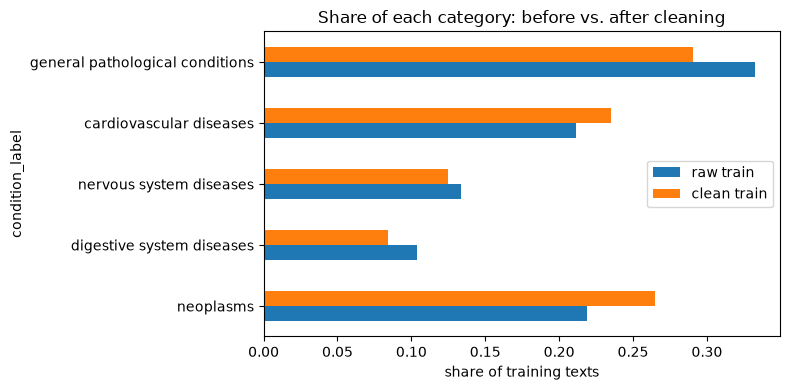

In [8]:
comparison = pd.DataFrame(
    {
        "raw train": train_df["condition_label"].value_counts(normalize=True),
        "clean train": train_clean["condition_label"].value_counts(normalize=True),
    }
).sort_index()
comparison.index = comparison.index.map(names)

comparison.plot.barh(figsize=(8, 4), title="Share of each category: before vs. after cleaning")
plt.xlabel("share of training texts")
plt.tight_layout()
plt.show()

*Digestive system diseases* and *general pathological conditions* lose roughly half of their texts. These are plausibly the categories that overlap most with the others (not verified).

The cleaned data is easier than real traffic, which will include ambiguous abstracts. Metrics computed on it are valid for single-category texts only, and the README states this limitation.

## 6. From category to urgency

The model predicts one of the 5 categories. Urgency is a lookup applied afterwards, defined in `configs/urgency_mapping.json`, so the rule can change without retraining.

In [9]:
mapping = json.loads((ROOT / "configs" / "urgency_mapping.json").read_text(encoding="utf-8"))
urgency_by_label = {int(label): info["urgency"] for label, info in mapping.items()}

display(pd.DataFrame(mapping).T.rename_axis("condition_label"))

urgency_share = train_clean["condition_label"].map(urgency_by_label).value_counts(normalize=True)
urgency_share.reindex(["urgent", "attention", "normal"]).round(3)

,category,urgency
condition_label,,
1,neoplasms,attention
2,digestive_system_diseases,attention
3,nervous_system_diseases,urgent
4,cardiovascular_diseases,urgent
5,general_pathological_conditions,normal


condition_label
urgent       0.360
attention    0.350
normal       0.291
Name: proportion, dtype: float64

The mapping is a **proxy**: it says how fast a *topic* typically needs care, not how sick a patient is, and it has no clinical validation. After the mapping, the three urgency levels are far less imbalanced than the five categories.

## 7. Takeaways

In [10]:
majority_baseline = test_clean["condition_label"].value_counts(normalize=True).max()
print(f"Always predicting the largest category scores {majority_baseline:.1%} on the clean test set")

Always predicting the largest category scores 28.0% on the clean test set


- **Floor to beat:** about 28% accuracy, from always predicting the largest category.
- **Metrics:** macro F1 over the 5 categories, and recall of the urgent class, because missing an urgent case is the costly error.
- **Imbalance:** handled with `class_weight="balanced"`.
- **Scope:** results hold for texts that belong to a single category.

Next: `src/train.py` trains and evaluates the model on this cleaned data.